# Near-miss combination: the near-misses together in the submitted linear model

Step 1 of `docs/next_steps.md`. Four changes that were each at least 0.3% better on at least
4 of 6 folds, but short of the 1% bar, combined in three nested candidates fixed before
running: (a) cap 5% + density 1 h, (b) (a) + WSA, (c) (b) + Bayes parr + mean. Six yearly
folds, official metric. Study `python -m training.near_miss`; write-up `docs/near_miss.md`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training import model_diagnostics as dg
from training import near_miss as nm

d = pd.read_csv(nm.EXPERIMENTS / "near_miss.csv", dtype={"fold": str})
ref = d[d.variant == "reference"].set_index("fold")
rows = {}
for v in nm.VARIANTS:
    g = d[d.variant == v].set_index("fold")
    rel = g["all"] / ref["all"]
    rows[v] = {"vs reference %": 100 * (np.exp(np.log(rel).mean()) - 1),
               "folds won": int((rel < 1).sum()),
               **{f"{r} %": 100 * (np.exp(np.log(g[r] / ref[r]).mean()) - 1)
                  for r in dg.RUN_REGIMES}}
summary = pd.DataFrame(rows).T
summary.round(2)

,vs reference %,folds won,CME %,stream arrival %,fast stream %,intermediate %,slow wind %
reference,0.00,0.0,0.00,0.00,0.00,0.00,0.00
cap 5%,-0.83,5.0,-0.11,-1.40,-2.88,-0.72,0.88
density 1h,-0.35,5.0,-0.09,-0.36,0.78,-0.32,-0.33
wsa,-0.75,4.0,-0.57,0.03,-1.91,-0.54,-2.98
bayes,-0.41,4.0,-0.70,-0.41,-2.49,0.12,-0.26
(a) cap + density,-1.08,5.0,0.24,-1.85,-1.65,-1.22,0.81
(b) (a) + wsa,-1.42,5.0,-0.09,-1.35,-3.83,-1.48,-1.67
(c) (b) + bayes,-1.92,5.0,-0.72,-1.72,-6.88,-1.00,-1.53


## By fold

S_final relative to the reference (the submitted config before the study: density 24 h, cap
0.5%). Below 1 is better.

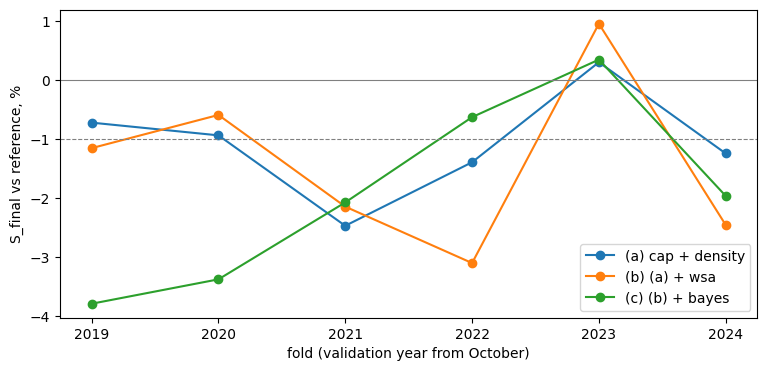

fold,2019,2020,2021,2022,2023,2024
variant,,,,,,
reference,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
cap 5%,0.9935,0.9985,0.9731,0.9880,1.0065,0.9906
density 1h,1.0011,0.9899,1.0000,0.9969,0.9949,0.9964
wsa,0.9981,1.0034,0.9950,0.9732,1.0051,0.9807
bayes,0.9766,0.9773,0.9988,1.0179,0.9954,1.0099
(a) cap + density,0.9928,0.9906,0.9753,0.9861,1.0030,0.9876
(b) (a) + wsa,0.9885,0.9941,0.9786,0.9690,1.0095,0.9755
(c) (b) + bayes,0.9621,0.9663,0.9793,0.9937,1.0035,0.9804


In [2]:
by_fold = d.pivot(index="variant", columns="fold", values="all")
by_fold = (by_fold / by_fold.loc["reference"]).loc[list(nm.VARIANTS)]
fig, ax = plt.subplots(figsize=(9, 4))
for v in nm.CANDIDATES:
    ax.plot(by_fold.columns, 100 * (by_fold.loc[v] - 1), marker="o", label=v)
ax.axhline(0, color="grey", lw=0.8)
ax.axhline(-1, color="grey", lw=0.8, ls="--")
ax.set_ylabel("S_final vs reference, %")
ax.set_xlabel("fold (validation year from October)")
ax.legend()
plt.show()
by_fold.round(4)

## The rule, and leave one fold out

Keep a candidate if it is more than 1% better, wins at least 4 of 6 folds and its slow-wind
runs are not more than 1% worse; the smallest passing set wins. The parts were picked on these
folds, so for each fold: what the rule picks on the other five.

In [3]:
rows_json = {y: {v: d[(d.fold == y) & (d.variant == v)].iloc[0].to_dict()
                for v in nm.VARIANTS} for y in sorted(d.fold.unique())}
years = sorted(rows_json)
pd.DataFrame({"picked": [nm.pick(rows_json, years)]
              + [nm.pick(rows_json, [z for z in years if z != y]) for y in years]},
             index=["all six"] + [f"without {y}" for y in years])

,picked
all six,(a) cap + density
without 2019,(a) cap + density
without 2020,(a) cap + density
without 2021,(b) (a) + wsa
without 2022,(b) (a) + wsa
without 2023,(a) cap + density
without 2024,(a) cap + density


## Eval year (descriptive, once)

(a) against the submitted model on the eval year (2025-10-20 → 2026-10-16, 1,448 runs, official
metric). Scored once after the choice; it is not part of the rule.

| | all | CME | stream arrival | fast stream | intermediate | slow wind |
|---|---|---|---|---|---|---|
| (a) | 118.51 | 142.94 | 100.95 | 80.86 | 68.87 | 63.43 |
| submitted model | 117.98 | 140.94 | 104.41 | 82.98 | 69.10 | 61.34 |
| change | +0.45% | +1.4% | −3.3% | −2.6% | −0.3% | +3.4% |

## Conclusion

Not submitted (user decision, 2026-11-17); (a) runs in staging as `upload_candidate/near-miss-a`.
- **All three candidates pass on the folds;** the rule picks the smallest, (a): −1.08%, 5 of 6,
  slow-wind runs +0.8%.
- **(a) is borderline:** without 2021 or 2022 it fails and (b) is picked instead.
- **The eval year doesn't confirm it:** +0.45% overall, better at stream arrivals and in fast
  streams, worse in slow wind (+3.4%) and CME runs (+1.4%).
- **(b) and (c) gain more on the folds** (−1.42%, −1.92%) and improve slow-wind runs, but each
  step over (a) wins only 3 of 6 folds, and they need WSA and Bayes code at runtime. Building
  them is in `docs/next_steps.md`.